In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Dashboard project setup started!")
print("Libraries imported successfully.")

Dashboard project setup started!
Libraries imported successfully.


In [2]:
from google.colab import files

uploaded = files.upload()

Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn.csv


In [3]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

# Convert TotalCharges into numeric format
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].astype(str).str.strip(),
    errors="coerce"
)

# Fill missing TotalCharges with 0
df["TotalCharges"] = df["TotalCharges"].fillna(0)

print("Dataset loaded and cleaned successfully!")
print("Dataset Shape:", df.shape)
print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())

display(df.head())

Dataset loaded and cleaned successfully!
Dataset Shape: (7043, 21)
Missing Values: 0
Duplicate Rows: 0


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
cleaned_file = "Telco_Customer_Churn_Cleaned.csv"

df.to_csv(cleaned_file, index=False)

print("Cleaned dataset saved successfully!")
files.download(cleaned_file)

Cleaned dataset saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [5]:
total_customers = df["customerID"].nunique()

churned_customers = (df["Churn"] == "Yes").sum()

churn_rate = (churned_customers / total_customers) * 100

print("========== CUSTOMER CHURN KPIs ==========")
print(f"Total Customers : {total_customers:,}")
print(f"Churned Customers: {churned_customers:,}")
print(f"Churn Rate      : {churn_rate:.2f}%")

========== CUSTOMER CHURN KPIs ==========
Total Customers : 7,043
Churned Customers: 1,869
Churn Rate      : 26.54%


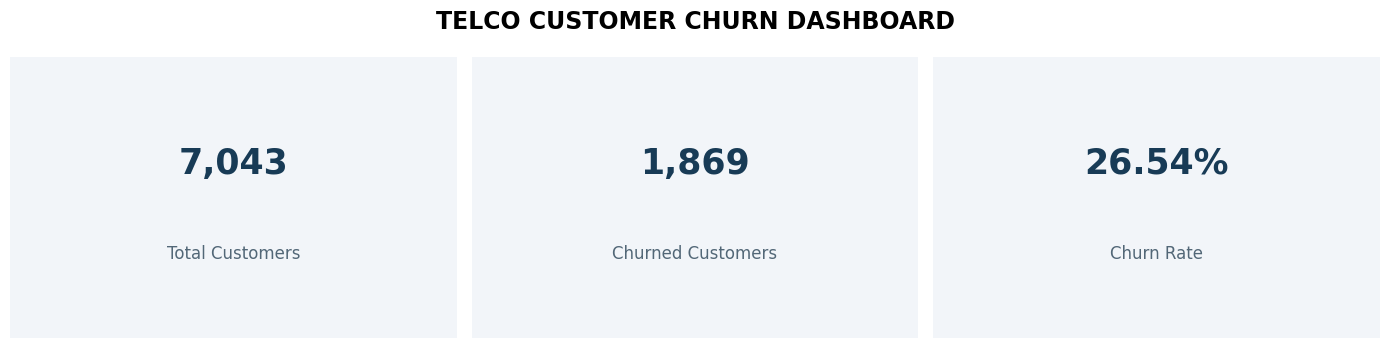

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))

kpis = [
    ("Total Customers", f"{total_customers:,}"),
    ("Churned Customers", f"{churned_customers:,}"),
    ("Churn Rate", f"{churn_rate:.2f}%")
]

for ax, (title, value) in zip(axes, kpis):
    ax.set_facecolor("#F2F5F9")
    ax.text(0.5, 0.62, value, ha="center", va="center",
            fontsize=25, fontweight="bold", color="#183B56")
    ax.text(0.5, 0.30, title, ha="center", va="center",
            fontsize=12, color="#526777")
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)

fig.suptitle("TELCO CUSTOMER CHURN DASHBOARD",
             fontsize=17, fontweight="bold")
plt.tight_layout()
plt.show()

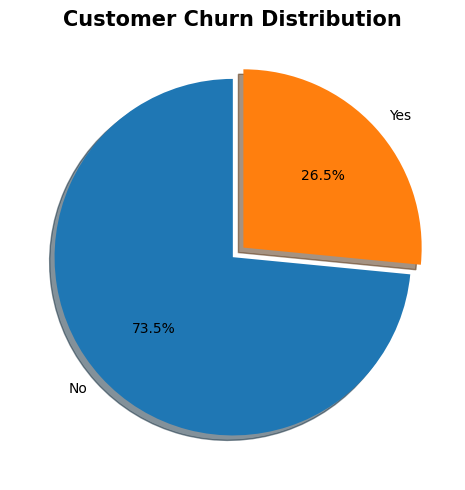

In [7]:
churn_counts = df["Churn"].value_counts()

plt.figure(figsize=(7, 5))

plt.pie(
    churn_counts,
    labels=churn_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    explode=(0, 0.08),
    shadow=True
)

plt.title("Customer Churn Distribution",
          fontsize=15, fontweight="bold")

plt.tight_layout()
plt.show()

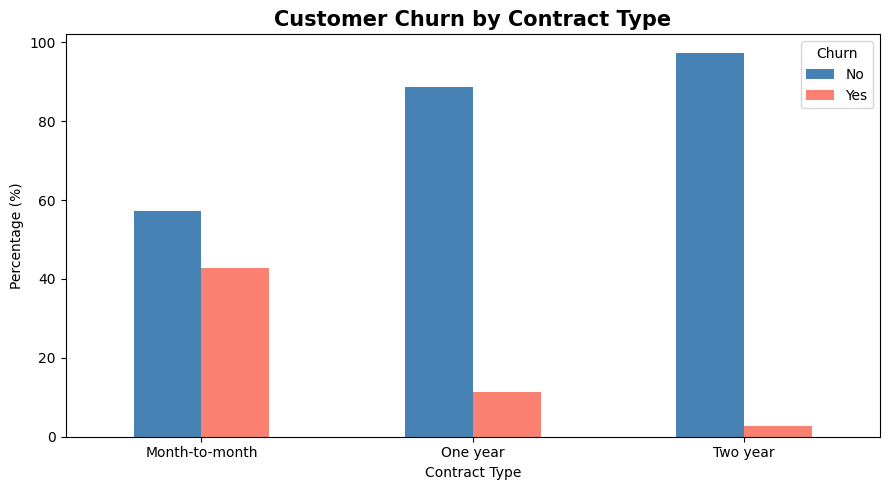

Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


In [8]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

contract_churn.plot(
    kind="bar",
    figsize=(9, 5),
    color=["steelblue", "salmon"]
)

plt.title("Customer Churn by Contract Type",
          fontsize=15, fontweight="bold")
plt.xlabel("Contract Type")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

display(contract_churn.round(2))

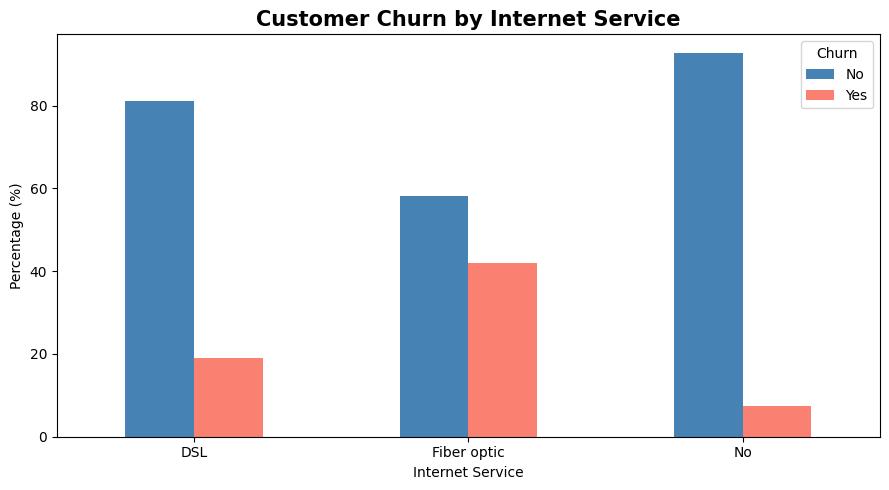

Churn,No,Yes
InternetService,,
DSL,81.04,18.96
Fiber optic,58.11,41.89
No,92.60,7.40


In [9]:
internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

internet_churn.plot(
    kind="bar",
    figsize=(9, 5),
    color=["steelblue", "salmon"]
)

plt.title("Customer Churn by Internet Service",
          fontsize=15, fontweight="bold")
plt.xlabel("Internet Service")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

display(internet_churn.round(2))

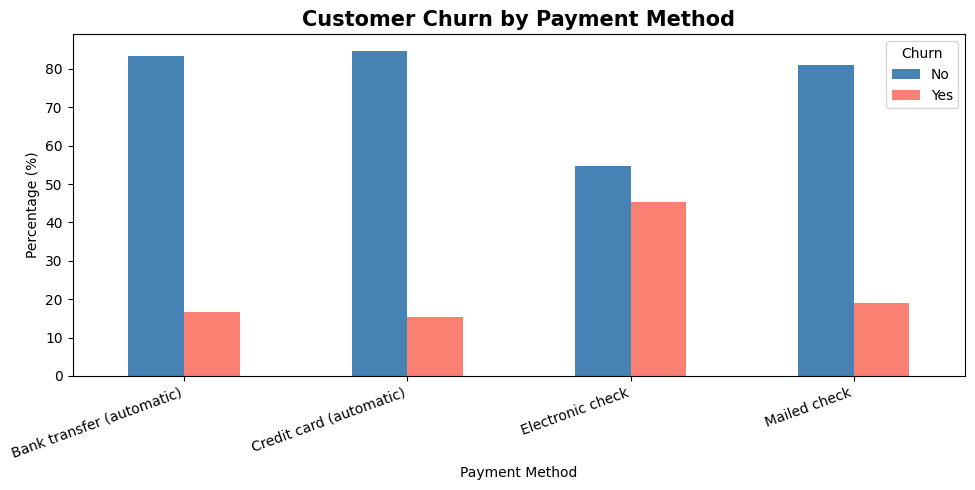

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.29,16.71
Credit card (automatic),84.76,15.24
Electronic check,54.71,45.29
Mailed check,80.89,19.11


In [10]:
payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

payment_churn.plot(
    kind="bar",
    figsize=(10, 5),
    color=["steelblue", "salmon"]
)

plt.title("Customer Churn by Payment Method",
          fontsize=15, fontweight="bold")
plt.xlabel("Payment Method")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=20, ha="right")
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

display(payment_churn.round(2))

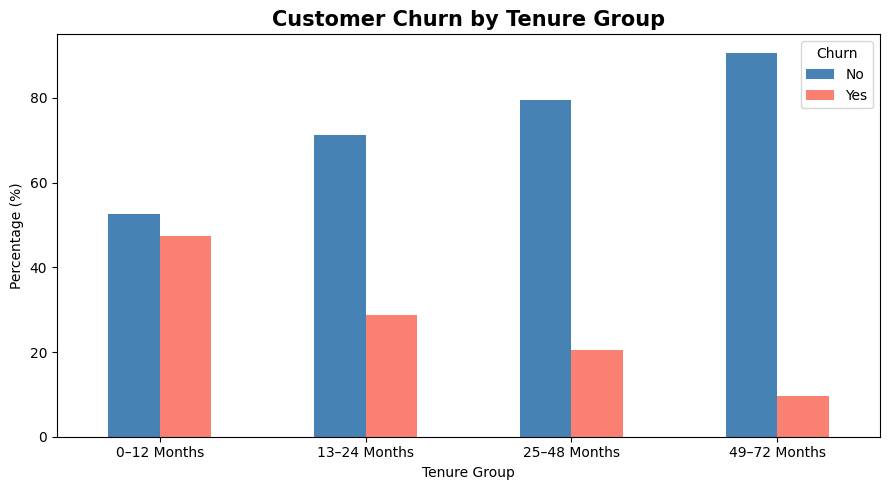

Churn,No,Yes
TenureGroup,,
0–12 Months,52.56,47.44
13–24 Months,71.29,28.71
25–48 Months,79.61,20.39
49–72 Months,90.49,9.51


In [11]:
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0–12 Months", "13–24 Months",
            "25–48 Months", "49–72 Months"]
)

tenure_churn = pd.crosstab(
    df["TenureGroup"],
    df["Churn"],
    normalize="index"
) * 100

tenure_churn.plot(
    kind="bar",
    figsize=(9, 5),
    color=["steelblue", "salmon"]
)

plt.title("Customer Churn by Tenure Group",
          fontsize=15, fontweight="bold")
plt.xlabel("Tenure Group")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

display(tenure_churn.round(2))

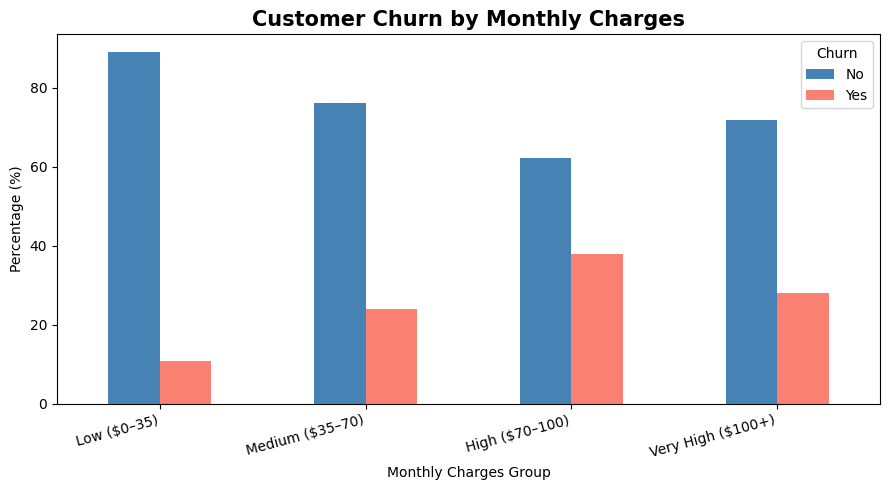

Churn,No,Yes
MonthlyChargesGroup,,
Low ($0–35),89.11,10.89
Medium ($35–70),76.06,23.94
High ($70–100),62.18,37.82
Very High ($100+),71.95,28.05


In [12]:
df["MonthlyChargesGroup"] = pd.cut(
    df["MonthlyCharges"],
    bins=[-1, 35, 70, 100, float("inf")],
    labels=["Low ($0–35)", "Medium ($35–70)",
            "High ($70–100)", "Very High ($100+)"]
)

charges_churn = pd.crosstab(
    df["MonthlyChargesGroup"],
    df["Churn"],
    normalize="index"
) * 100

charges_churn.plot(
    kind="bar",
    figsize=(9, 5),
    color=["steelblue", "salmon"]
)

plt.title("Customer Churn by Monthly Charges",
          fontsize=15, fontweight="bold")
plt.xlabel("Monthly Charges Group")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=15, ha="right")
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

display(charges_churn.round(2))

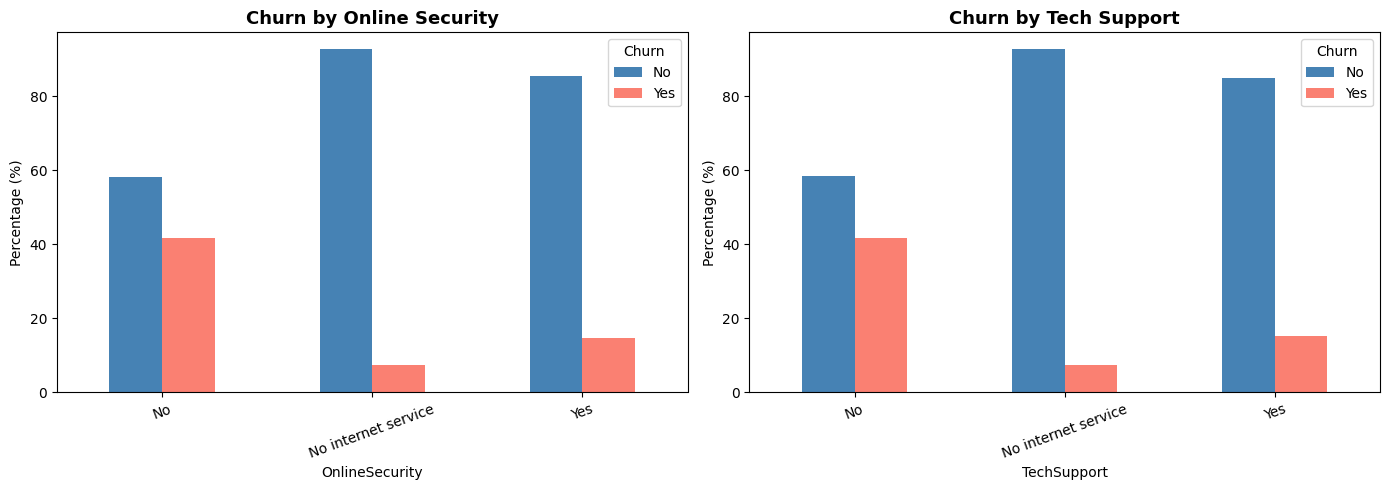

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, column, title in zip(
    axes,
    ["OnlineSecurity", "TechSupport"],
    ["Churn by Online Security", "Churn by Tech Support"]
):
    service_churn = pd.crosstab(
        df[column],
        df["Churn"],
        normalize="index"
    ) * 100

    service_churn.plot(
        kind="bar",
        ax=ax,
        color=["steelblue", "salmon"]
    )

    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel(column)
    ax.set_ylabel("Percentage (%)")
    ax.tick_params(axis="x", rotation=20)
    ax.legend(title="Churn")

plt.tight_layout()
plt.show()

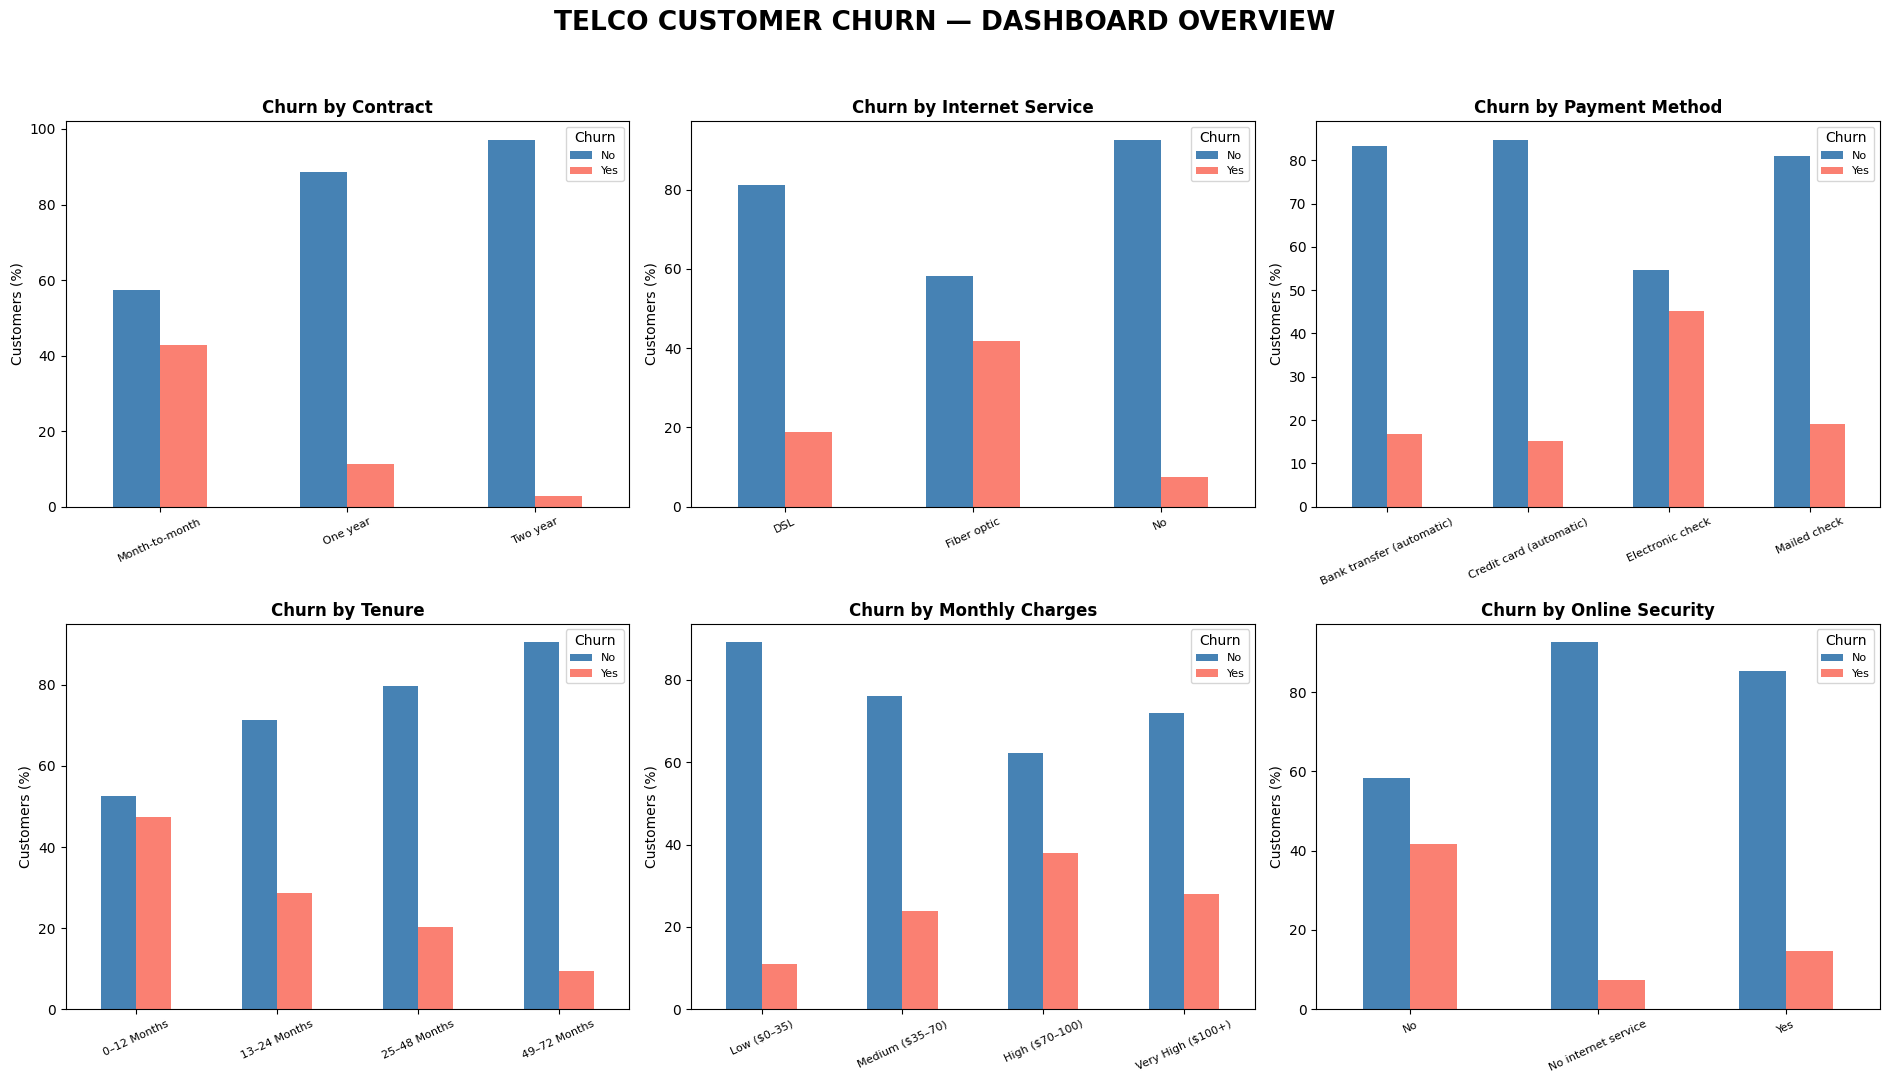

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(19, 11))

chart_columns = [
    ("Contract", "Churn by Contract"),
    ("InternetService", "Churn by Internet Service"),
    ("PaymentMethod", "Churn by Payment Method"),
    ("TenureGroup", "Churn by Tenure"),
    ("MonthlyChargesGroup", "Churn by Monthly Charges"),
    ("OnlineSecurity", "Churn by Online Security")
]

for ax, (column, title) in zip(axes.flat, chart_columns):
    churn_data = pd.crosstab(
        df[column],
        df["Churn"],
        normalize="index"
    ) * 100

    churn_data.plot(
        kind="bar",
        ax=ax,
        color=["steelblue", "salmon"]
    )

    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("Customers (%)")
    ax.tick_params(axis="x", rotation=25, labelsize=8)
    ax.legend(title="Churn", fontsize=8)

fig.suptitle(
    "TELCO CUSTOMER CHURN — DASHBOARD OVERVIEW",
    fontsize=19,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

In [15]:
!pip -q install streamlit plotly

In [16]:
%%writefile app.py

import streamlit as st
import pandas as pd
import plotly.express as px

# Page configuration
st.set_page_config(
    page_title="Telco Customer Churn Dashboard",
    page_icon="📊",
    layout="wide"
)

# Load cleaned dataset
df = pd.read_csv("Telco_Customer_Churn_Cleaned.csv")

# Create analysis groups
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0–12 Months", "13–24 Months",
            "25–48 Months", "49–72 Months"]
)

df["MonthlyChargesGroup"] = pd.cut(
    df["MonthlyCharges"],
    bins=[-1, 35, 70, 100, float("inf")],
    labels=["Low ($0–35)", "Medium ($35–70)",
            "High ($70–100)", "Very High ($100+)"]
)

# Dashboard title
st.title("📊 Telco Customer Churn Dashboard")
st.caption("Interactive analysis of customer churn patterns")

# Sidebar filters
st.sidebar.header("Customer Filters")

contract_filter = st.sidebar.multiselect(
    "Contract Type",
    options=df["Contract"].unique(),
    default=df["Contract"].unique()
)

internet_filter = st.sidebar.multiselect(
    "Internet Service",
    options=df["InternetService"].unique(),
    default=df["InternetService"].unique()
)

gender_filter = st.sidebar.multiselect(
    "Gender",
    options=df["gender"].unique(),
    default=df["gender"].unique()
)

# Apply filters
filtered_df = df[
    (df["Contract"].isin(contract_filter)) &
    (df["InternetService"].isin(internet_filter)) &
    (df["gender"].isin(gender_filter))
]

# KPI calculations
total_customers = len(filtered_df)
churned_customers = (filtered_df["Churn"] == "Yes").sum()
churn_rate = (
    churned_customers / total_customers * 100
    if total_customers > 0 else 0
)

# KPI cards
col1, col2, col3 = st.columns(3)

col1.metric("Total Customers", f"{total_customers:,}")
col2.metric("Churned Customers", f"{churned_customers:,}")
col3.metric("Churn Rate", f"{churn_rate:.2f}%")

st.divider()

if total_customers == 0:
    st.warning("No customers match the selected filters.")
else:
    # Churn distribution
    st.subheader("Customer Churn Distribution")

    churn_counts = filtered_df["Churn"].value_counts().reset_index()
    churn_counts.columns = ["Churn", "Customers"]

    fig = px.pie(
        churn_counts,
        names="Churn",
        values="Customers",
        hole=0.4,
        title="Churn Distribution"
    )
    st.plotly_chart(fig, use_container_width=True)

    # Churn analysis helper
    def churn_chart(column, title):
        data = pd.crosstab(
            filtered_df[column],
            filtered_df["Churn"],
            normalize="index"
        ).reset_index()

        data = data.melt(
            id_vars=column,
            var_name="Churn",
            value_name="Percentage"
        )

        data["Percentage"] *= 100

        fig = px.bar(
            data,
            x=column,
            y="Percentage",
            color="Churn",
            barmode="group",
            title=title,
            text_auto=".1f"
        )

        fig.update_layout(
            yaxis_title="Customers (%)",
            xaxis_title=""
        )

        st.plotly_chart(fig, use_container_width=True)

    # Customer segment charts
    st.subheader("Churn Analysis by Customer Segment")

    col1, col2 = st.columns(2)

    with col1:
        churn_chart("Contract", "Churn by Contract Type")
        churn_chart("InternetService", "Churn by Internet Service")
        churn_chart("PaymentMethod", "Churn by Payment Method")
        churn_chart("OnlineSecurity", "Churn by Online Security")

    with col2:
        churn_chart("TenureGroup", "Churn by Tenure")
        churn_chart("MonthlyChargesGroup", "Churn by Monthly Charges")
        churn_chart("TechSupport", "Churn by Tech Support")

    # Filtered data preview
    with st.expander("View Filtered Customer Data"):
        st.dataframe(filtered_df, use_container_width=True)

st.caption("Project: Telco Customer Churn Analysis | Python, Pandas, Plotly & Streamlit")

Writing app.py


In [17]:
import os

for filename in [
    "app.py",
    "Telco_Customer_Churn_Cleaned.csv"
]:
    print(
        filename,
        "✅ Found" if os.path.exists(filename) else "❌ Missing"
    )

app.py ✅ Found
Telco_Customer_Churn_Cleaned.csv ✅ Found


In [18]:
!streamlit run app.py &>/content/streamlit.log &

In [19]:
!npm install -g localtunnel

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙
added 22 packages in 3s
⠙
⠙3 packages are looking for funding
⠙  run `npm fund` for details
⠙

In [24]:
print("----- STREAMLIT LOG -----")

!cat /content/streamlit.log

print("\n----- SERVER STATUS -----")

!ps aux | grep streamlit

----- STREAMLIT LOG -----


2026-10-30 15:46:35.806 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://8.228.18.19:8501

  Stopping...

----- SERVER STATUS -----
root        8349  0.0  0.0   7344  3476 ?        S    16:06   0:00 /bin/bash -c ps aux | grep streamlit
root        8351  0.0  0.0   6548  2352 ?        S    16:06   0:00 grep streamlit


In [22]:
!lt --port 8501

your url is: https://purple-coats-enter.loca.lt
^C


In [25]:
!pkill -f streamlit || true

^C


In [26]:
!nohup streamlit run app.py --server.port 8501 --server.address 0.0.0.0 > /content/streamlit.log 2>&1 < /dev/null &

In [27]:
import requests

try:
    response = requests.get("http://127.0.0.1:8501", timeout=10)
    print("Status Code:", response.status_code)
    print("Streamlit server is responding ✅")
except Exception as e:
    print("Streamlit server is not responding ❌")
    print(e)

print("\n----- Recent Streamlit Logs -----")
!tail -20 /content/streamlit.log

Status Code: 200
Streamlit server is responding ✅

----- Recent Streamlit Logs -----


2026-10-30 16:13:09.823 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://8.228.18.19:8501



In [ ]:
!lt --port 8501

your url is: https://six-mice-throw.loca.lt
